# Notebook 5: Cell-Type Scoring

## The problem
This dataset uses bulk RNA-seq: each sample is a mixture of many cell types
(neurons, astrocytes, microglia, oligodendrocytes, endothelial cells).
We cannot directly see which cell type expresses each channel.

## The approach
I estimate cell-type composition using marker gene scores (the average
expression of well-established marker genes for each cell type) taken from
published human single-cell RNA-seq studies.

If PIEZO2 expression correlates strongly with the astrocyte score but not
the neuron score, it suggests PIEZO2 is primarily expressed in astrocytes.

## Marker genes used
From Zhang et al. 2016 (Cell): human brain cell-type specific genes:
- Astrocytes: GFAP, AQP4, SLC1A2, ALDH1L1
- Microglia: CX3CR1, P2RY12, TMEM119, IBA1 (AIF1)
- Neurons: SNAP25, SYT1, RBFOX3, MAP2
- Oligodendrocytes: MBP, MOG, PLP1, MAG
- Endothelial: CLDN5, PECAM1, VWF, FLT1

## Limitation
This is a rough estimate only, not true deconvolution.
Results suggest which cell type a channel is associated with,
but cannot prove it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
from statsmodels.stats.multitest import multipletests
import warnings
warnings.filterwarnings('ignore')

PROJECT_ROOT = Path("..").resolve()
DATA_DIR     = PROJECT_ROOT / "data"
FIGURES_DIR  = PROJECT_ROOT / "figures"

# load master table
merged = pd.read_csv(DATA_DIR / "master_analysis_table.csv")

# log-transform target genes
target_genes = [
    'PIEZO1', 'PIEZO2', 'TRPV4', 'TRPV1', 'TRPV2',
    'KCNK2', 'KCNK4', 'KCNK10', 'TMEM63A', 'TMEM63B'
]
for gene in target_genes:
    merged[f'{gene}_log2'] = np.log2(merged[gene] + 1)

# load full expression matrix and gene lookup
print("Loading expression matrix...")
fpkm      = pd.read_csv(DATA_DIR / "fpkm_table_normalized.csv", index_col=0)
genes_ref = pd.read_csv(DATA_DIR / "rows-genes.csv")
samples   = pd.read_csv(DATA_DIR / "columns-samples.csv")

print(f"Expression matrix: {fpkm.shape}")
print("Ready.")

Loading expression matrix...
Expression matrix: (50281, 377)
Ready.


In [ ]:
# ── cell type marker genes ─────────────────────────────────────────────────
# from Zhang et al. 2016 (Cell): human brain single-cell RNA-seq
# these are well-established markers used widely in the field

cell_type_markers = {
    'Astrocyte':      ['GFAP', 'AQP4', 'SLC1A2', 'ALDH1L1'],
    'Microglia':      ['CX3CR1', 'P2RY12', 'TMEM119', 'AIF1'],
    'Neuron':         ['SNAP25', 'SYT1', 'RBFOX3', 'MAP2'],
    'Oligodendrocyte':['MBP', 'MOG', 'PLP1', 'MAG'],
    'Endothelial':    ['CLDN5', 'PECAM1', 'VWF', 'FLT1'],
}

# ── find gene IDs for marker genes ────────────────────────────────────────
print("Checking marker genes in dataset:\n")
marker_ids = {}   # cell_type -> list of gene_ids found

for cell_type, markers in cell_type_markers.items():
    found = []
    missing = []
    for marker in markers:
        match = genes_ref[genes_ref['gene_symbol'] == marker]
        if len(match) > 0:
            found.append(match['gene_id'].values[0])
        else:
            missing.append(marker)
    marker_ids[cell_type] = found
    print(f"{cell_type:20s} found: {len(found)}/4  {f'missing: {missing}' if missing else ''}")

Checking marker genes in dataset:

Astrocyte            found: 4/4  
Microglia            found: 4/4  
Neuron               found: 4/4  
Oligodendrocyte      found: 4/4  
Endothelial          found: 4/4  


In [3]:
# ── calculate cell-type scores ─────────────────────────────────────────────
# score = average log2 expression of marker genes for that cell type
# one score per sample per cell type

# first get marker gene expression from the full matrix
# and link to samples

# build a symbol -> gene_id lookup
symbol_to_id = dict(zip(genes_ref['gene_symbol'], genes_ref['gene_id']))

# link samples to rnaseq_profile_id
sample_ids = samples['rnaseq_profile_id'].astype(str).tolist()
fpkm.columns = fpkm.columns.astype(str)

scores = {}

for cell_type, gene_ids in marker_ids.items():
    # extract marker rows from expression matrix
    marker_expr = fpkm.loc[fpkm.index.isin(gene_ids)]
    
    # log2 transform
    marker_log2 = np.log2(marker_expr + 1)
    
    # average across markers (column = sample)
    score = marker_log2.mean(axis=0)
    scores[cell_type] = score

# build scores dataframe — one row per sample
scores_df = pd.DataFrame(scores)
scores_df.index.name = 'rnaseq_profile_id'
scores_df.index = scores_df.index.astype(int)
scores_df = scores_df.reset_index()

print(f"Cell-type scores shape: {scores_df.shape}")
print(f"\nFirst 3 rows:")
scores_df.head(3)

Cell-type scores shape: (377, 6)

First 3 rows:


,rnaseq_profile_id,Astrocyte,Microglia,Neuron,Oligodendrocyte,Endothelial
0,488395315,7.530437,2.304729,7.157819,7.249358,3.667794
1,496100277,7.540852,3.170308,0.603427,9.594567,4.207198
2,496100278,7.729816,3.274893,0.295783,9.993715,4.212950


In [4]:
# merge cell-type scores with master table
merged_ct = merged.merge(scores_df, on='rnaseq_profile_id', how='left')

print(f"Merged shape: {merged_ct.shape}")
print(f"\nMean cell-type scores by brain region:")
region_map = {
    'temporal neocortex': 'TCx',
    'hippocampus (hippocampal formation)': 'HIP',
    'white matter of forebrain': 'FWM',
    'parietal neocortex': 'PCx'
}
merged_ct['region'] = merged_ct['structure_name'].map(region_map)

cell_types = ['Astrocyte', 'Microglia', 'Neuron', 'Oligodendrocyte', 'Endothelial']
print(merged_ct.groupby('region')[cell_types].mean().round(2))


Merged shape: (377, 38)

Mean cell-type scores by brain region:
        Astrocyte  Microglia  Neuron  Oligodendrocyte  Endothelial
region                                                            
FWM          7.56       2.96    5.77             8.79         3.80
HIP          8.03       3.32    6.94             7.52         3.86
PCx          7.58       2.57    7.23             6.80         3.83
TCx          7.47       2.58    7.32             6.86         3.73


In [ ]:
# ── correlate channel expression with cell-type scores ─────────────────────
# same approach as notebook 4 but now asking: which cell type does each channel associate with?

log_genes = [f'{gene}_log2' for gene in target_genes]
ct_results = []

for gene_col in log_genes:
    for ct in cell_types:
        valid = merged_ct[[gene_col, ct]].dropna()
        rho, pval = stats.spearmanr(valid[gene_col], valid[ct])
        ct_results.append({
            'gene':      gene_col.replace('_log2', ''),
            'cell_type': ct,
            'rho':       rho,
            'pval':      pval,
            'n':         len(valid)
        })

ct_df = pd.DataFrame(ct_results)

# FDR correction
_, ct_df['qval'], _, _ = multipletests(ct_df['pval'], method='fdr_bh')
ct_df = ct_df.round(4)

print("Top correlations between channels and cell-type scores:")
print(ct_df.sort_values('pval').head(15).to_string(index=False))

Top correlations between channels and cell-type scores:
   gene       cell_type     rho  pval   n   qval
 PIEZO1       Astrocyte  0.2159   0.0 377 0.0000
 KCNK10          Neuron  0.4155   0.0 377 0.0000
 KCNK10       Microglia -0.2469   0.0 377 0.0000
TMEM63A          Neuron -0.8000   0.0 377 0.0000
  KCNK4 Oligodendrocyte -0.3164   0.0 377 0.0000
  KCNK4          Neuron  0.3853   0.0 377 0.0000
TMEM63A Oligodendrocyte  0.9467   0.0 377 0.0000
  KCNK4       Astrocyte  0.2190   0.0 377 0.0000
  KCNK2 Oligodendrocyte -0.2950   0.0 377 0.0000
  KCNK2          Neuron  0.3465   0.0 377 0.0000
TMEM63B Oligodendrocyte -0.4798   0.0 377 0.0000
  TRPV2 Oligodendrocyte -0.3435   0.0 377 0.0000
  TRPV2          Neuron  0.4016   0.0 377 0.0000
TMEM63A       Astrocyte  0.2136   0.0 377 0.0001
  TRPV1 Oligodendrocyte  0.6885   0.0 377 0.0000


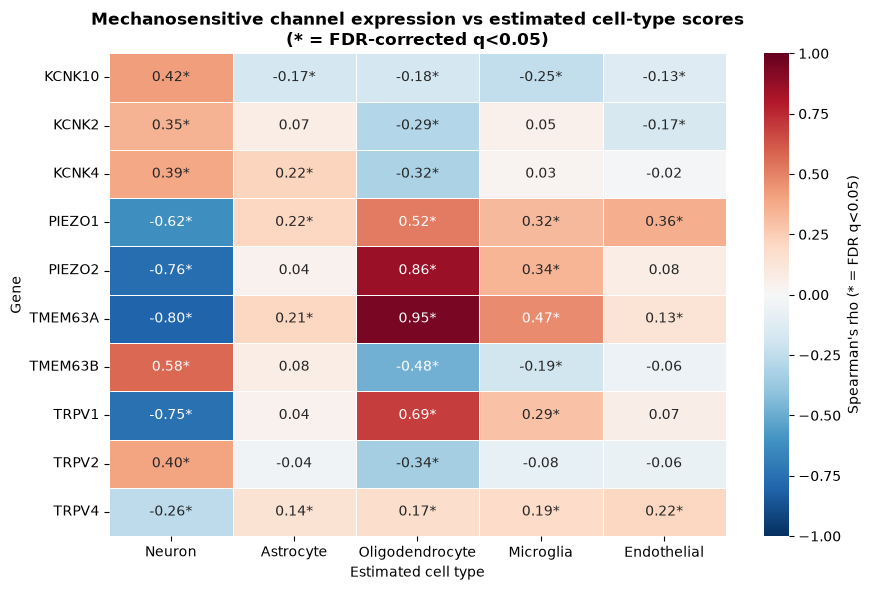

Saved.


In [7]:
# pivot for heatmap
pivot_ct_rho  = ct_df.pivot(index='gene', columns='cell_type', values='rho')
pivot_ct_qval = ct_df.pivot(index='gene', columns='cell_type', values='qval')

# annotation with *
annot_ct = pivot_ct_rho.copy().astype(str)
for gene in pivot_ct_rho.index:
    for ct in pivot_ct_rho.columns:
        rho = pivot_ct_rho.loc[gene, ct]
        q   = pivot_ct_qval.loc[gene, ct]
        val = f"{rho:.2f}"
        if q < 0.05:
            val = f"{rho:.2f}*"
        annot_ct.loc[gene, ct] = val

# reorder columns biologically
ct_order = ['Neuron', 'Astrocyte', 'Oligodendrocyte', 'Microglia', 'Endothelial']
pivot_ct_rho  = pivot_ct_rho[ct_order]
annot_ct      = annot_ct[ct_order]

fig, ax = plt.subplots(figsize=(9, 6))

sns.heatmap(pivot_ct_rho, ax=ax,
            cmap='RdBu_r', center=0,
            vmin=-1, vmax=1,
            annot=annot_ct, fmt='',
            linewidths=0.5, linecolor='white',
            cbar_kws={'label': "Spearman's rho (* = FDR q<0.05)"})

ax.set_title('Mechanosensitive channel expression vs estimated cell-type scores\n(* = FDR-corrected q<0.05)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Estimated cell type')
ax.set_ylabel('Gene')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '05_cell_type_scores.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved.")